In [1]:
import zipfile, glob, os
import pandas as pd

zips = glob.glob("/content/*.zip")
assert zips, "No zip found. Do Step 2 first."
zip_path = zips[0]
print("Zip file:", zip_path, "-", round(os.path.getsize(zip_path) / 1024 / 1024, 1), "MB")
assert zipfile.is_zipfile(zip_path), "Zip is broken (incomplete upload). Delete it and upload again."

with zipfile.ZipFile(zip_path) as z:
    z.extractall("/content/oulad")

info_path = glob.glob("/content/oulad/**/studentInfo.csv", recursive=True)[0]
path = os.path.dirname(info_path) + "/"

student_info = pd.read_csv(path + "studentInfo.csv")
print(student_info.shape)
print(student_info["final_result"].value_counts())

Zip file: /content/anonymisedData.zip - 44.6 MB
(32593, 12)
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64


In [2]:
import numpy as np

DAYS = 60
keys = ["code_module", "code_presentation", "id_student"]
course = ["code_module", "code_presentation"]

info = pd.read_csv(path + "studentInfo.csv")
reg = pd.read_csv(path + "studentRegistration.csv")
vle = pd.read_csv(path + "studentVle.csv")
sa = pd.read_csv(path + "studentAssessment.csv")
assess = pd.read_csv(path + "assessments.csv")
vle_info = pd.read_csv(path + "vle.csv")[["id_site", "activity_type"]]

# Student info + registration, keep only students still active at day 60
df = info.merge(reg, on=keys, how="left")
df = df[df["date_unregistration"].isna() | (df["date_unregistration"] > DAYS)]

# Target: 1 = Withdrawn (dropout), 0 = stayed
df["dropout"] = (df["final_result"] == "Withdrawn").astype(int)

# Online activity in the first 60 days, split into two halves
early_vle = vle[vle["date"] <= DAYS].copy()
early_vle["first30"] = np.where(early_vle["date"] <= 30, early_vle["sum_click"], 0)
early_vle["next30"] = np.where(early_vle["date"] > 30, early_vle["sum_click"], 0)
clicks = early_vle.groupby(keys).agg(
    total_clicks=("sum_click", "sum"),
    clicks_first30=("first30", "sum"),
    clicks_next30=("next30", "sum"),
    active_days=("date", "nunique"),
    first_activity_day=("date", "min")
).reset_index()
clicks["click_trend"] = clicks["clicks_next30"] - clicks["clicks_first30"]
clicks["clicks_per_active_day"] = clicks["total_clicks"] / clicks["active_days"]

# NEW: activity-type detail and recency
ev = early_vle.merge(vle_info, on="id_site", how="left")

by_type = ev.pivot_table(index=keys, columns="activity_type", values="sum_click",
                         aggfunc="sum", fill_value=0)
by_type.columns = ["clicks_" + str(c) for c in by_type.columns]
type_cols = list(by_type.columns)
by_type = by_type.reset_index()

extra = ev.groupby(keys).agg(
    last_activity_day=("date", "max"),
    distinct_pages=("id_site", "nunique"),
    distinct_types=("activity_type", "nunique"),
).reset_index()
extra["days_since_last_activity"] = DAYS - extra["last_activity_day"]
recent = ev[ev["date"] > DAYS - 14].groupby(keys)["sum_click"].sum().reset_index(name="clicks_last14")
extra = extra.merge(recent, on=keys, how="left").drop(columns=["last_activity_day"])

# Assessments: submitted, score, lateness
assess_info = assess[["id_assessment", "code_module", "code_presentation", "date"]].rename(columns={"date": "due_date"})
sa2 = sa.merge(assess_info, on="id_assessment", how="left")
early_sa = sa2[sa2["date_submitted"] <= DAYS].copy()
early_sa["delay"] = early_sa["date_submitted"] - early_sa["due_date"]
scores = early_sa.groupby(keys).agg(
    assessments_done=("id_assessment", "count"),
    avg_score=("score", "mean"),
    avg_delay=("delay", "mean")
).reset_index()

# Assessments due by day 60 in each course
due = assess_info[assess_info["due_date"] <= DAYS].groupby(course).size().reset_index(name="assessments_due")

# Combine everything
df = (df.merge(clicks, on=keys, how="left")
        .merge(scores, on=keys, how="left")
        .merge(due, on=course, how="left")
        .merge(by_type, on=keys, how="left")
        .merge(extra, on=keys, how="left"))

zero_cols = ["total_clicks", "clicks_first30", "clicks_next30", "active_days", "click_trend",
             "clicks_per_active_day", "assessments_done", "avg_score", "avg_delay", "assessments_due",
             "distinct_pages", "distinct_types", "clicks_last14"] + type_cols
df[zero_cols] = df[zero_cols].fillna(0)
df["first_activity_day"] = df["first_activity_day"].fillna(DAYS)
df["days_since_last_activity"] = df["days_since_last_activity"].fillna(DAYS)
df["assessments_missed"] = (df["assessments_due"] - df["assessments_done"]).clip(lower=0)
df["date_registration"] = df["date_registration"].fillna(df["date_registration"].median())
df["imd_band"] = df["imd_band"].fillna("Unknown")

# Remove columns that would leak the answer, convert text to numbers
df = df.drop(columns=["id_student", "final_result", "date_unregistration"])
df = pd.get_dummies(df, columns=["code_module", "code_presentation", "gender", "region",
                                 "highest_education", "imd_band", "age_band", "disability"])

print("Final table size:", df.shape)
print("Dropout rate:", round(df["dropout"].mean() * 100, 1), "%")

Final table size: (26361, 86)
Dropout rate: 14.9 %


In [3]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, precision_score, roc_auc_score

X = df.drop("dropout", axis=1).astype(float)
y = df["dropout"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

log_model = LogisticRegression(max_iter=1000, class_weight="balanced")
log_model.fit(X_train_scaled, y_train)
log_pred = log_model.predict(X_test_scaled)
log_proba = log_model.predict_proba(X_test_scaled)[:, 1]

rf_model = RandomForestClassifier(n_estimators=200, min_samples_leaf=5,
                                  class_weight="balanced", random_state=42)
rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)
rf_proba = rf_model.predict_proba(X_test)[:, 1]

results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest"],
    "Accuracy %": [round(accuracy_score(y_test, log_pred) * 100, 1), round(accuracy_score(y_test, rf_pred) * 100, 1)],
    "Dropouts caught % (recall)": [round(recall_score(y_test, log_pred) * 100, 1), round(recall_score(y_test, rf_pred) * 100, 1)],
    "Correct when flagged % (precision)": [round(precision_score(y_test, log_pred) * 100, 1), round(precision_score(y_test, rf_pred) * 100, 1)],
    "AUC score": [round(roc_auc_score(y_test, log_proba), 3), round(roc_auc_score(y_test, rf_proba), 3)],
})
print(results.to_string(index=False))

              Model  Accuracy %  Dropouts caught % (recall)  Correct when flagged % (precision)  AUC score
Logistic Regression        67.2                        62.9                                25.6      0.706
      Random Forest        83.8                        20.9                                41.3      0.724


In [4]:
import numpy as np
import pandas as pd

def reach_table(proba, name):
    order = np.argsort(-proba)
    y_sorted = y_test.values[order]
    total = y_sorted.sum()
    rows = []
    for pct in [10, 20, 30, 40]:
        n = int(len(y_sorted) * pct / 100)
        found = y_sorted[:n].sum()
        rows.append([f"Top {pct}% riskiest", n, int(found), round(found / total * 100, 1)])
    print(name)
    print(pd.DataFrame(rows, columns=["Students checked", "Number", "Dropouts found", "% of all dropouts reached"]).to_string(index=False))
    print()

def reach_curve(proba):
    order = np.argsort(-proba)
    y_sorted = y_test.values[order]
    return np.cumsum(y_sorted) / y_sorted.sum() * 100

x = np.arange(1, len(y_test) + 1) / len(y_test) * 100

In [5]:
import xgboost as xgb
import re

# Clean column names for XGBoost compatibility (remove [, ], <)
def clean_column_names(df_to_clean):
    cleaned_cols = []
    for col in df_to_clean.columns:
        col_str = str(col)
        # Replace forbidden characters with underscores
        col_str = re.sub(r'[\\\[\]\<\>]', '_', col_str)
        cleaned_cols.append(col_str)
    df_to_clean.columns = cleaned_cols
    return df_to_clean

# Create clean copies of the features
X_train_clean = clean_column_names(X_train.copy())
X_test_clean = clean_column_names(X_test.copy())

# Train XGBoost model using the same training split
# We compute scale_pos_weight to handle class imbalance
imbalance_ratio = (len(y_train) - y_train.sum()) / y_train.sum()

xgb_model = xgb.XGBClassifier(
    n_estimators=200,
    max_depth=5,
    scale_pos_weight=imbalance_ratio,
    random_state=42,
    eval_metric="logloss"
)
xgb_model.fit(X_train_clean, y_train)

xgb_pred = xgb_model.predict(X_test_clean)
xgb_proba = xgb_model.predict_proba(X_test_clean)[:, 1]

# Update the results table with XGBoost
results = pd.DataFrame({
    "Model": ["Logistic Regression", "Random Forest", "XGBoost"],
    "Accuracy %": [
        round(accuracy_score(y_test, log_pred) * 100, 1),
        round(accuracy_score(y_test, rf_pred) * 100, 1),
        round(accuracy_score(y_test, xgb_pred) * 100, 1)
    ],
    "Dropouts caught % (recall)": [
        round(recall_score(y_test, log_pred) * 100, 1),
        round(recall_score(y_test, rf_pred) * 100, 1),
        round(recall_score(y_test, xgb_pred) * 100, 1)
    ],
    "Correct when flagged % (precision)": [
        round(precision_score(y_test, log_pred) * 100, 1),
        round(precision_score(y_test, rf_pred) * 100, 1),
        round(precision_score(y_test, xgb_pred) * 100, 1)
    ],
    "AUC score": [
        round(roc_auc_score(y_test, log_proba), 3),
        round(roc_auc_score(y_test, rf_proba), 3),
        round(roc_auc_score(y_test, xgb_proba), 3)
    ],
})
print(results.to_string(index=False))

              Model  Accuracy %  Dropouts caught % (recall)  Correct when flagged % (precision)  AUC score
Logistic Regression        67.2                        62.9                                25.6      0.706
      Random Forest        83.8                        20.9                                41.3      0.724
            XGBoost        79.1                        35.7                                31.9      0.685


In [6]:
reach_table(xgb_proba, "XGBoost")

XGBoost
Students checked  Number  Dropouts found  % of all dropouts reached
Top 10% riskiest    1054             374                       23.8
Top 20% riskiest    2109             641                       40.8
Top 30% riskiest    3163             804                       51.1
Top 40% riskiest    4218             988                       62.8



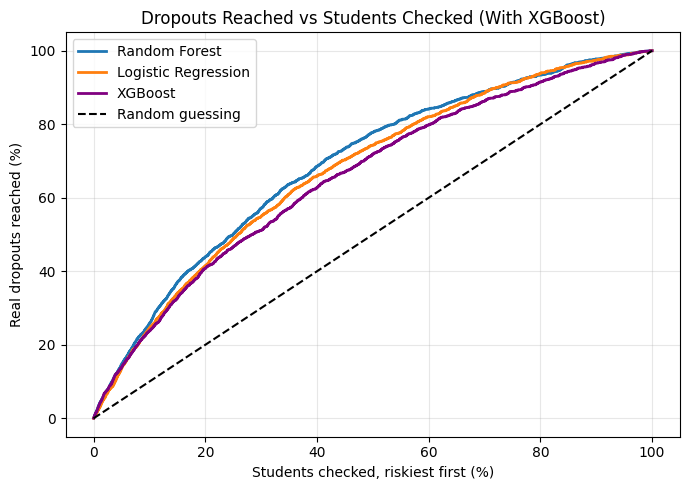

In [7]:
# Updated Chart 2: Dropouts reached vs students checked including XGBoost
import matplotlib.pyplot as plt
import seaborn as sns
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, reach_curve(rf_proba), label="Random Forest", linewidth=2)
ax.plot(x, reach_curve(log_proba), label="Logistic Regression", linewidth=2)
ax.plot(x, reach_curve(xgb_proba), label="XGBoost", linewidth=2, color="purple")
ax.plot([0, 100], [0, 100], "k--", label="Random guessing")
ax.set_title("Dropouts Reached vs Students Checked (With XGBoost)")
ax.set_xlabel("Students checked, riskiest first (%)")
ax.set_ylabel("Real dropouts reached (%)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
import numpy as np

def reach_table(proba, name):
    order = np.argsort(-proba)
    y_sorted = y_test.values[order]
    total = y_sorted.sum()
    rows = []
    for pct in [10, 20, 30, 40]:
        n = int(len(y_sorted) * pct / 100)
        found = y_sorted[:n].sum()
        rows.append([f"Top {pct}% riskiest", n, int(found), round(found / total * 100, 1)])
    print(name)
    print(pd.DataFrame(rows, columns=["Students checked", "Number", "Dropouts found", "% of all dropouts reached"]).to_string(index=False))
    print()

reach_table(rf_proba, "Random Forest")
reach_table(log_proba, "Logistic Regression")
print("Random guessing would reach only 10%, 20%, 30%, 40% in these rows.")

Random Forest
Students checked  Number  Dropouts found  % of all dropouts reached
Top 10% riskiest    1054             405                       25.7
Top 20% riskiest    2109             691                       43.9
Top 30% riskiest    3163             898                       57.1
Top 40% riskiest    4218            1078                       68.5

Logistic Regression
Students checked  Number  Dropouts found  % of all dropouts reached
Top 10% riskiest    1054             385                       24.5
Top 20% riskiest    2109             653                       41.5
Top 30% riskiest    3163             864                       54.9
Top 40% riskiest    4218            1036                       65.9

Random guessing would reach only 10%, 20%, 30%, 40% in these rows.


In [9]:
import numpy as np
from sklearn.metrics import roc_auc_score

rng = np.random.default_rng(42)

# One random guess: give every student a random risk score between 0 and 1
random_scores = rng.random(len(y_test))
reach_table(random_scores, "Random guessing (simulated)")
print("AUC of random guessing:", round(roc_auc_score(y_test, random_scores), 3))

# Repeat 100 times and average, to make it stable
reach_20 = []
for _ in range(100):
    s = rng.random(len(y_test))
    order = np.argsort(-s)
    n = int(len(y_test) * 0.20)
    reach_20.append(y_test.values[order][:n].sum() / y_test.sum() * 100)
print("Average reach in the top 20% over 100 random runs:", round(np.mean(reach_20), 1), "%")

Random guessing (simulated)
Students checked  Number  Dropouts found  % of all dropouts reached
Top 10% riskiest    1054             161                       10.2
Top 20% riskiest    2109             338                       21.5
Top 30% riskiest    3163             468                       29.8
Top 40% riskiest    4218             609                       38.7

AUC of random guessing: 0.502
Average reach in the top 20% over 100 random runs: 19.9 %


In [10]:
risk_df = X_test[["total_clicks", "active_days", "assessments_missed", "avg_score"]].copy()
risk_df["Dropout risk score"] = rf_proba
risk_df["Actual outcome"] = y_test.map({1: "Dropped out", 0: "Stayed"})
risk_df = risk_df.sort_values("Dropout risk score", ascending=False)

n = len(risk_df)
risk_df["Risk level"] = "Low"
risk_df.iloc[: int(n * 0.30), risk_df.columns.get_loc("Risk level")] = "Medium"
risk_df.iloc[: int(n * 0.10), risk_df.columns.get_loc("Risk level")] = "High"

summary = risk_df.groupby("Risk level").agg(
    Students=("Actual outcome", "count"),
    Dropped_out=("Actual outcome", lambda s: (s == "Dropped out").sum())
).reindex(["High", "Medium", "Low"])
summary["Real dropout rate %"] = (summary["Dropped_out"] / summary["Students"] * 100).round(1)
print(summary)
print()
print(risk_df.head(10).round(2).to_string())

risk_df.round(3).to_csv("at_risk_students.csv", index=True)

            Students  Dropped_out  Real dropout rate %
Risk level                                            
High            1054          405                 38.4
Medium          2109          493                 23.4
Low             7382          675                  9.1

       total_clicks  active_days  assessments_missed  avg_score  Dropout risk score Actual outcome Risk level
8619          381.0         18.0                 1.0       11.0                0.80    Dropped out       High
9334           56.0          6.0                 2.0        0.0                0.78    Dropped out       High
7521           80.0         12.0                 2.0        0.0                0.76         Stayed       High
8280          245.0         18.0                 0.0        7.0                0.75    Dropped out       High
13257         262.0         22.0                 1.0       71.0                0.73         Stayed       High
7644          227.0         17.0                 0.0       17.0 

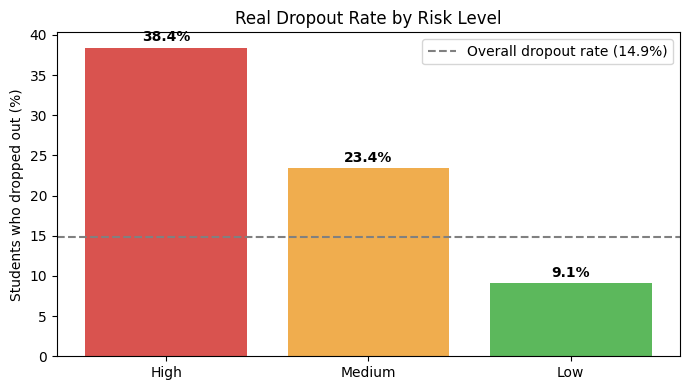

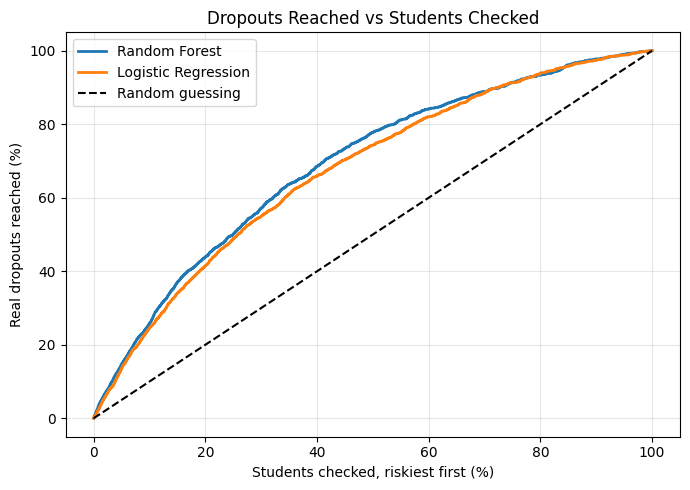

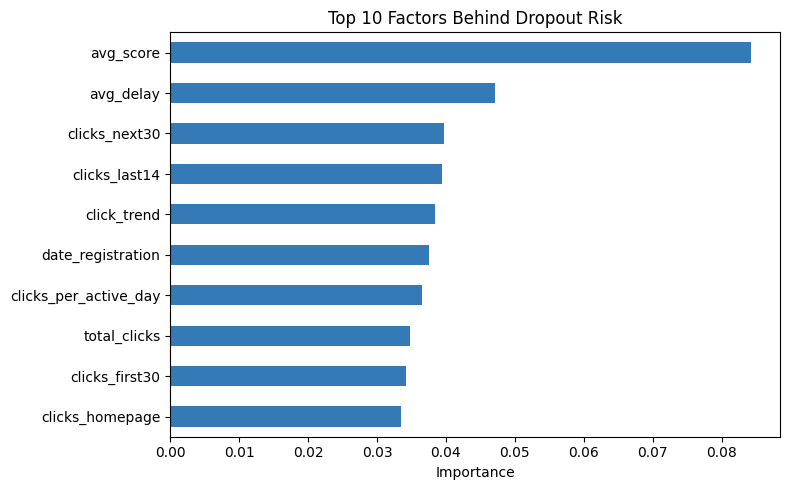

In [11]:
import matplotlib.pyplot as plt

# Chart 1: real dropout rate by risk level
fig, ax = plt.subplots(figsize=(7, 4))
rates = summary["Real dropout rate %"]
bars = ax.bar(rates.index, rates.values, color=["#d9534f", "#f0ad4e", "#5cb85c"])
ax.axhline(y=14.9, color="gray", linestyle="--", label="Overall dropout rate (14.9%)")
for bar, val in zip(bars, rates.values):
    ax.text(bar.get_x() + bar.get_width() / 2, val + 0.8, f"{val}%", ha="center", fontweight="bold")
ax.set_title("Real Dropout Rate by Risk Level")
ax.set_ylabel("Students who dropped out (%)")
ax.legend()
plt.tight_layout()
plt.show()

# Chart 2: dropouts reached vs students checked
def reach_curve(proba):
    order = np.argsort(-proba)
    y_sorted = y_test.values[order]
    return np.cumsum(y_sorted) / y_sorted.sum() * 100

x = np.arange(1, len(y_test) + 1) / len(y_test) * 100
fig, ax = plt.subplots(figsize=(7, 5))
ax.plot(x, reach_curve(rf_proba), label="Random Forest", linewidth=2)
ax.plot(x, reach_curve(log_proba), label="Logistic Regression", linewidth=2)
ax.plot([0, 100], [0, 100], "k--", label="Random guessing")
ax.set_title("Dropouts Reached vs Students Checked")
ax.set_xlabel("Students checked, riskiest first (%)")
ax.set_ylabel("Real dropouts reached (%)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

# Chart 3: top factors
imp = pd.Series(rf_model.feature_importances_, index=X.columns).sort_values(ascending=False).head(10)
fig, ax = plt.subplots(figsize=(8, 5))
imp.sort_values().plot(kind="barh", ax=ax, color="#337ab7")
ax.set_title("Top 10 Factors Behind Dropout Risk")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.show()

In [12]:
print("Number of features:", X.shape[1])

Number of features: 85


In [13]:
import joblib, sklearn, numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from google.colab import files

web_features = ["total_clicks", "active_days", "clicks_first30", "clicks_next30",
                "assessments_done", "assessments_missed", "avg_score", "avg_delay",
                "num_of_prev_attempts", "studied_credits"]

Xw = df[web_features].astype(float)
yw = df["dropout"]
Xw_train, Xw_test, yw_train, yw_test = train_test_split(
    Xw, yw, test_size=0.3, random_state=42, stratify=yw
)

web_model = RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                   class_weight="balanced", random_state=42, n_jobs=-1)
web_model.fit(Xw_train, yw_train)
proba = web_model.predict_proba(Xw_test)[:, 1]
print("AUC of website model:", round(roc_auc_score(yw_test, proba), 3))

# Risk cutoffs: top 10% = High, next 20% = Medium, same as your project
high_cut = float(np.quantile(proba, 0.90))
medium_cut = float(np.quantile(proba, 0.70))
print("High cutoff:", round(high_cut, 3), "| Medium cutoff:", round(medium_cut, 3))

joblib.dump({"model": web_model, "features": web_features,
             "high_cut": high_cut, "medium_cut": medium_cut},
            "dropout_model.joblib", compress=3)
print("scikit-learn version:", sklearn.__version__)
files.download("dropout_model.joblib")

AUC of website model: 0.712
High cutoff: 0.645 | Medium cutoff: 0.481
scikit-learn version: 1.6.1


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [14]:
import numpy as np
from sklearn.metrics import roc_auc_score

levels = np.where(proba >= high_cut, "High", np.where(proba >= medium_cut, "Medium", "Low"))
check = pd.DataFrame({"level": levels, "dropped": yw_test.values})
out = check.groupby("level")["dropped"].agg(Students="count", Dropped_out="sum")
out["Real dropout rate %"] = (out["Dropped_out"] / out["Students"] * 100).round(1)
print(out.reindex(["High", "Medium", "Low"]))
print()
print("Website model AUC:", round(roc_auc_score(yw_test, proba), 3))
print("Overall dropout rate in test set:", round(yw_test.mean() * 100, 1), "%")

        Students  Dropped_out  Real dropout rate %
level                                             
High         791          292                 36.9
Medium      1582          359                 22.7
Low         5536          529                  9.6

Website model AUC: 0.712
Overall dropout rate in test set: 14.9 %
